# Reading data

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
data_root = "class_statistics_csvs/"
df_only_visual_2_query = pd.read_csv(data_root+"only_visual_2_query.csv")
df_only_visual_5_query = pd.read_csv(data_root+"only_visual_5_query.csv")
df_replacement_30 = pd.read_csv(data_root+"replacement_30.csv")
df_replacement_40 = pd.read_csv(data_root+"replacement_40.csv")
df_replacement_50 = pd.read_csv(data_root+"replacement_50.csv")
df_replacement_70 = pd.read_csv(data_root+"replacement_70.csv")
df_replacement_100 = pd.read_csv(data_root+"replacement_100.csv")
df_oversampling_30 = pd.read_csv(data_root+"oversampling_30.csv")
df_oversampling_50 = pd.read_csv(data_root+"oversampling_50.csv")
df_oversampling_100 = pd.read_csv(data_root+"oversampling_100.csv")

In [25]:
dataframes_to_concat = []

sources = [
    (df_only_visual_2_query, "only_visual_2_query"),
    (df_only_visual_5_query, "only_visual_5_query"),
    (df_replacement_30, "replacement_30"),
    (df_replacement_40, "replacement_40"),
    (df_replacement_50, "replacement_50"),
    (df_replacement_70, "replacement_70"),
    (df_replacement_100, "replacement_100"),
    (df_oversampling_30, "oversampling_30"),
    (df_oversampling_50, "oversampling_50"),
    (df_oversampling_100, "oversampling_100")    
]

for df, source_name in sources:
    df_copy = df.copy()
    df_copy['model'] = source_name
    dataframes_to_concat.append(df_copy)

merged_df = pd.concat(dataframes_to_concat, ignore_index=True)
merged_df.head(2)

,class_id,precision,recall,f1_score,gt_count,pred_count,model
0,0,0.666667,0.837264,0.742290,848,1065,only_visual_2_query
1,1,0.250000,0.333333,0.285714,6,8,only_visual_2_query


# Per-class means

## Functions

In [26]:
# Attach model groups for colouring plots
def get_model_group(model):
    if model.startswith('only_visual'):
        return 'Visual-only'
    elif model.startswith('replacement'):
        return 'Replacement'
    elif model.startswith('oversampling'):
        return 'Oversampling'
    else:
        return 'Other'

## All classes

In [16]:
means = merged_df.groupby("model").agg(precision_mean=('precision', 'mean'), recall_mean=('recall', 'mean'), f1_mean_mean=('f1_score', 'mean'))
means

,precision_mean,recall_mean,f1_mean_mean
model,,,
only_visual_2_query,0.114909,0.121519,0.112646
only_visual_5_query,0.131233,0.128444,0.122584
oversampling_100,0.109002,0.114522,0.107582
oversampling_30,0.111197,0.117584,0.108934
oversampling_50,0.107878,0.114520,0.106140
replacement_100,0.001792,0.002653,0.001439
replacement_30,0.108003,0.106335,0.101856
replacement_40,0.110887,0.117551,0.110959
replacement_50,0.107362,0.110741,0.103088


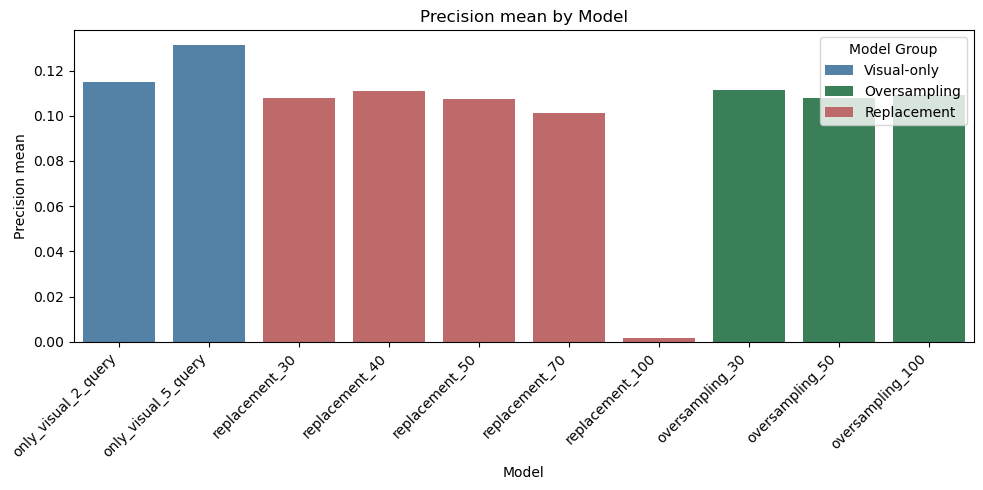

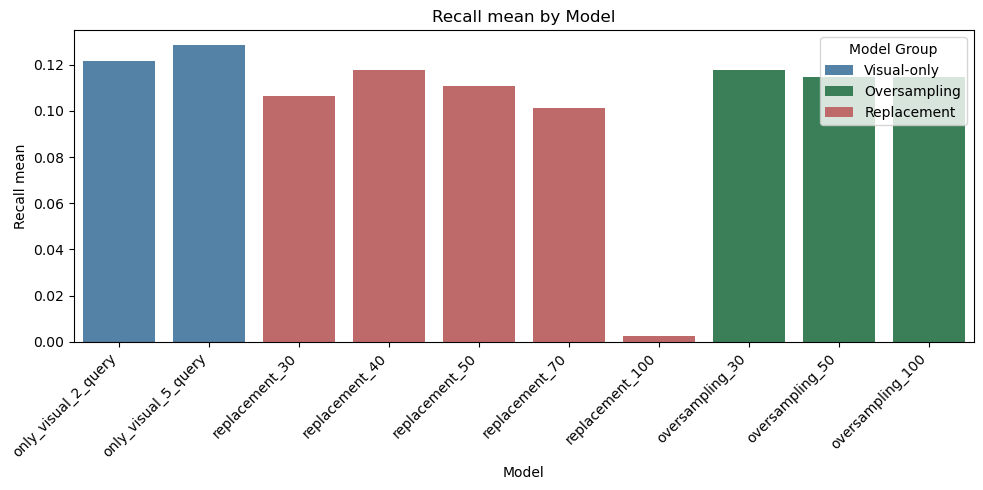

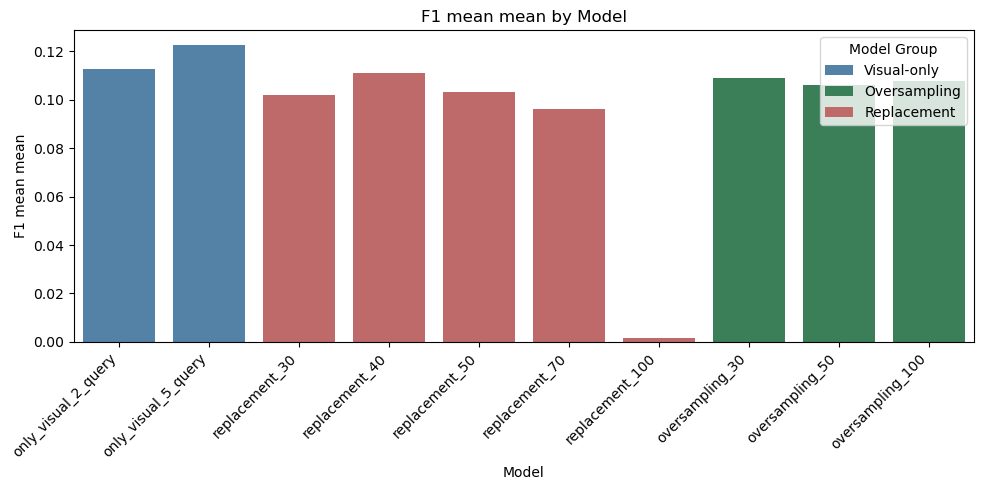

In [29]:
means_long = means.reset_index().rename(columns={'index': 'model'}).melt(id_vars='model', var_name='metric', value_name='value')
palette = {
    'Visual-only': 'steelblue',
    'Replacement': 'indianred',
    'Oversampling': 'seagreen'
}
means_long['group'] = means_long['model'].apply(get_model_group)

model_order = [
    'only_visual_2_query', 'only_visual_5_query',
    'replacement_30', 'replacement_40', 'replacement_50',
    'replacement_70', 'replacement_100',
    'oversampling_30', 'oversampling_50', 'oversampling_100'
]

for metric in ['precision_mean', 'recall_mean', 'f1_mean_mean']:
    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=means_long[means_long['metric'] == metric],
        x='model', y='value',
        order=model_order,
        hue='group',
        dodge=False,
        palette=palette
    )
    plt.xticks(rotation=45, ha='right')
    plt.title(f'{metric.replace("_", " ").capitalize()} by Model')
    plt.ylabel(metric.replace("_", " ").capitalize())
    plt.xlabel('Model')
    plt.legend(title='Model Group')
    plt.tight_layout()
    plt.show()

## With classes that appear at least 5 times

In [35]:
popular_classes_df = merged_df[merged_df["gt_count"] >= 5]
print(f"Nr of classes in evaluation changed from {len(merged_df[merged_df['model'] == 'only_visual_2_query'])} to {len(popular_classes_df[popular_classes_df['model'] == 'only_visual_2_query'])}")
means = popular_classes_df.groupby("model").agg(precision_mean=('precision', 'mean'), recall_mean=('recall', 'mean'), f1_mean_mean=('f1_score', 'mean'))
means

Nr of classes in evaluation changed from 365 to 73


,precision_mean,recall_mean,f1_mean_mean
model,,,
only_visual_2_query,0.433561,0.444351,0.430788
only_visual_5_query,0.472145,0.441309,0.440629
oversampling_100,0.437818,0.447038,0.429008
oversampling_30,0.411789,0.438379,0.416457
oversampling_50,0.427291,0.464153,0.435234
replacement_100,0.008962,0.013266,0.007197
replacement_30,0.436703,0.443778,0.428480
replacement_40,0.449412,0.470174,0.449456
replacement_50,0.408387,0.436126,0.409201


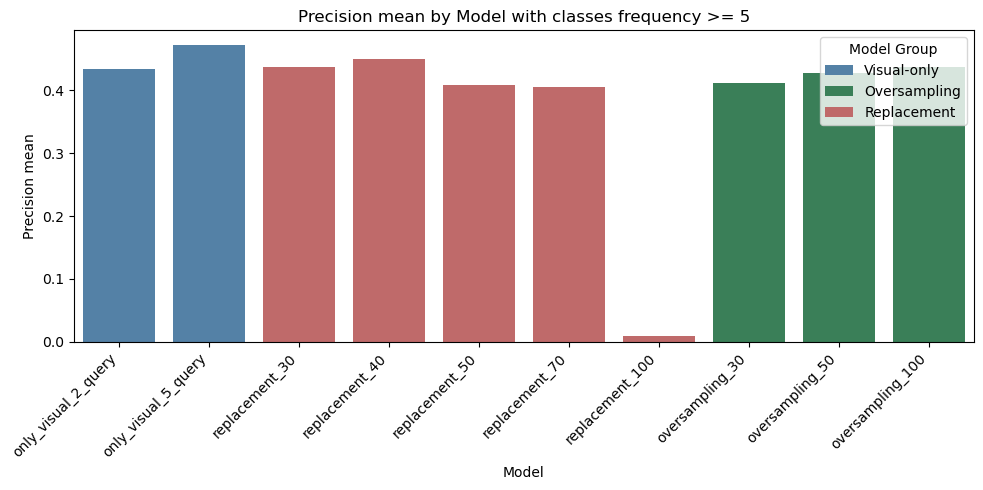

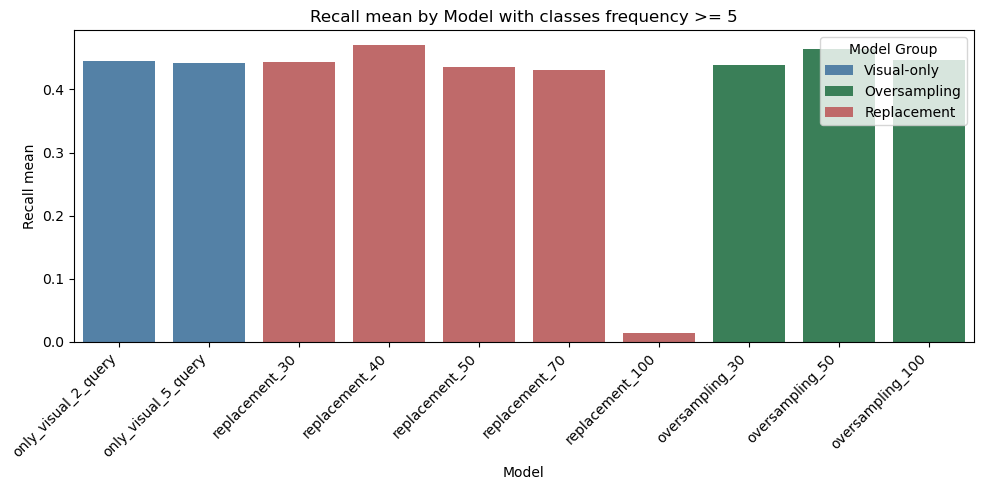

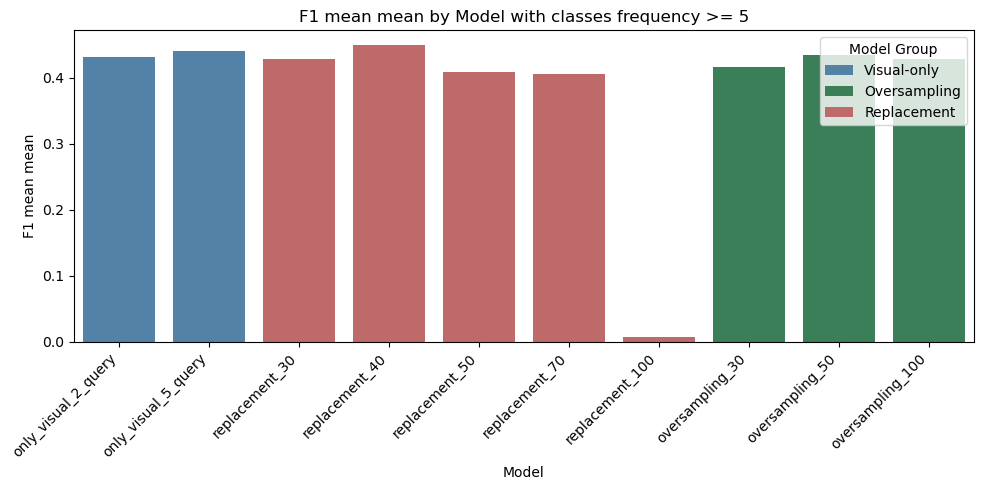

In [37]:
means_long = means.reset_index().rename(columns={'index': 'model'}).melt(id_vars='model', var_name='metric', value_name='value')
palette = {
    'Visual-only': 'steelblue',
    'Replacement': 'indianred',
    'Oversampling': 'seagreen'
}
means_long['group'] = means_long['model'].apply(get_model_group)

model_order = [
    'only_visual_2_query', 'only_visual_5_query',
    'replacement_30', 'replacement_40', 'replacement_50',
    'replacement_70', 'replacement_100',
    'oversampling_30', 'oversampling_50', 'oversampling_100'
]

for metric in ['precision_mean', 'recall_mean', 'f1_mean_mean']:
    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=means_long[means_long['metric'] == metric],
        x='model', y='value',
        order=model_order,
        hue='group',
        dodge=False,
        palette=palette
    )
    plt.xticks(rotation=45, ha='right')
    plt.title(f'{metric.replace("_", " ").capitalize()} by Model with classes frequency >= 5')
    plt.ylabel(metric.replace("_", " ").capitalize())
    plt.xlabel('Model')
    plt.legend(title='Model Group')
    plt.tight_layout()
    plt.show()

# Oversampling benefits
In which cases does a classes recall become better when oversampling with textual data. For reference let's just take the baseline 5 queries model and the seemingly best-performing oversampling with 30% 

In [38]:
better_recall = 

,class_id,precision,recall,f1_score,gt_count,pred_count,model
0,0,0.666667,0.837264,0.742290,848,1065,only_visual_2_query
1,1,0.250000,0.333333,0.285714,6,8,only_visual_2_query
2,2,0.965517,1.000000,0.982456,28,29,only_visual_2_query
3,3,0.500000,1.000000,0.666667,1,2,only_visual_2_query
4,4,0.000000,0.000000,0.000000,4,1,only_visual_2_query
...,...,...,...,...,...,...,...
3645,360,0.428571,0.666667,0.521739,9,14,oversampling_100
3646,361,0.000000,0.000000,0.000000,2,0,oversampling_100
3647,362,0.880000,0.814815,0.846154,27,25,oversampling_100
3648,363,0.340909,0.340909,0.340909,44,44,oversampling_100


In [52]:
df_oversampling_30_class_as_index = df_oversampling_30.set_index("class_id")
df_only_visual_5_query_class_as_index = df_only_visual_5_query.set_index("class_id")

model_a = "oversampling_30"
model_b = "only_visual_5_query"

# Join on class_id
comparison_df = df_oversampling_30_class_as_index[["recall"]].join(df_only_visual_5_query_class_as_index[["recall"]], lsuffix=f"_{model_a}", rsuffix=f"_{model_b}", how="inner")

# Filter where model A has higher recall than model B
better_recall_df = comparison_df[comparison_df[f"recall_{model_a}"] > comparison_df[f"recall_{model_b}"]]
unchanged_df = comparison_df[comparison_df[f"recall_{model_a}"] == comparison_df[f"recall_{model_b}"]]
# Reset index if needed
better_recall_df = better_recall_df.reset_index()
print(f"Oversampling increased recall in {len(better_recall_df)} classes out of 365, {len(unchanged_df)} class recalls were left unchanged")

Oversampling increased recall in 29 classes out of 365, 296 class recalls were left unchanged


# Predicting most popular class

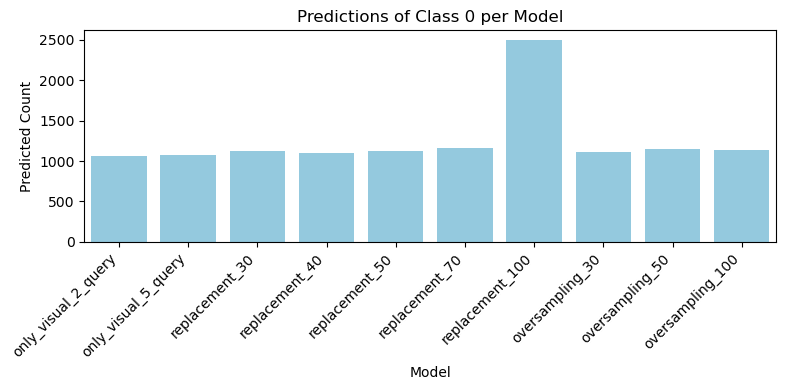

In [54]:
# Filter only rows for class_id == 0
class0_df = merged_df[merged_df['class_id'] == 0]

# Create bar plot
plt.figure(figsize=(8, 4))
sns.barplot(data=class0_df, x='model', y='pred_count', color='skyblue')
plt.title('Predictions of Class 0 per Model')
plt.ylabel('Predicted Count')
plt.xlabel('Model')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()